In [1]:
# Import packages
import sys
sys.path.append("./../")

import numpy as np
import torch
import random

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.neighbors import NearestNeighbors

from scripts.utils import load_array, load_model, load_param_dict

This notebook contains code for analyzing and visualizing the stability of C-SHAP based on the similarity between similar samples.

Both the updated RRS used in our main article, the original RRS [1] and the stability metric originally introduced by Alvarez-Melis and Jaakkola [2] can be selected.

* [1] Agarwal, Chirag, Nari Johnson, Martin Pawelczyk, Satyapriya Krishna, Eshika Saxena, Marinka Zitnik, and Himabindu Lakkaraju. "Rethinking stability for attribution-based explanations." arXiv preprint arXiv:2203.06877 (2022).
* [2] Alvarez-Melis, David, and Tommi S. Jaakkola. "On the robustness of interpretability methods." arXiv preprint arXiv:1806.08049 (2018).

In [2]:
metric = 'rrs_updated'          # Select metric: rrs_updated (ours), rrs ([1]) or stability ([2])
normalize_data = True           # Normalize SHAP values and embeddings/test data
normalize_length = True         # Scale numerator and denominator in metrics by the length of explanations/input samples/embeddings
norm = 1                        # Order of the norm (1: L1-norm, 2: L2-norm)

<h2> Initialization </h2>
Start with initialization and loading the data and SHAP values and defining the functions used later.

In [3]:
# Set seeds
import random

random.seed(10)
np.random.seed(10)

In [4]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
batch_size = 32

In [5]:
size_neighbourhood = 5 # Number of neighbouring samples to consider

In [6]:
def stability(x, y_pred, shap_values, similarity_f, norm_order=norm, epsilon=10e-10):
    """
    Calculate stability (log scaled) with respect to the given representation of a sample
    using the sample's neighbours for an array of samples.
    x: the representations of a set of samples, can be their raw input, model output or embedding
    y_pred: model predictions for the samples
    shap_values: previously calculated SHAP values for the samples
    similarity_f: function to use to determine nearest neighbours of a sample should receive an index of a sample in x
    and should return indices referring to samples in x
    norm_order: order of the norm used for measuring similarity between samples and SHAP values
    epsilon: tolerance for denominator
    returns: relative stability for the given samples
    """
    n_samples = len(x)                  # Determine number of samples
    stab_list = [None] * n_samples        # For storing relative stability of each sample
    for i in range(n_samples):          # Iterate through samples
        nns = similarity_f(i)           # Determine nearest neighbour of given sample
        if len(nns) <= 0:               # Skip if no neighbours
            continue
        rs_set = [None] * len(nns)      # For storing results of each NN pair

        for j, nn in enumerate(nns):    # Iterate through NN
            s1 = shap_values[i, :, y_pred[i]]         # Extract SHAP values
            s_nn = shap_values[nn, :, y_pred[i]]

            x1 = x[i]                                       # Extract representation values
            x_nn = x[nn]

            # Calculate intermediate RS for this pair and store it
            if metric == 'rrs_updated' or metric == 'stability':    # The updated RRS or original stability [2]
                numerator = np.linalg.norm(s1 - s_nn, ord=norm_order)
                denominator = np.max([np.linalg.norm(x1 - x_nn, ord=norm_order), epsilon])
            elif metric == 'rrs':                                   # The original RRS [1]
                numerator = np.linalg.norm((s1 - s_nn) / s1, ord=norm_order)
                denominator = np.max([np.linalg.norm((x1 - x_nn) / x1, ord=norm_order), epsilon])

            if normalize_length:                                    # Scale by lengths
                numerator /= len(s1)
                denominator /= len(x1)

            rs_set[j] = numerator / denominator                     # Calculate stability

        # Calculate final stability (log scaled) for this sample
        stab_list[i] = np.log(np.max(rs_set)) 
    return stab_list

In [7]:
def nearest_neighbors(idx, indices, predictions, same_class=True, n=1):
    """
    Extract nearest neighbours indices from lists of indices provided by scikit learn's NearestNeighbor class
    x: idx of sample to determine NN for
    indices: returned by sklearn's NearestNeighbor.kneighbors
    predictions: predictions for the samples in case NN are required to be of the same class
    same_class: whether NN should be of the same class
    n: number of samples
    returns: selected indices
    """
    if same_class is True:
        idx_list = indices[idx]
        same_class = idx_list[1:][[(predictions[idx_list[0]] == predictions[i]) for i in idx_list[1:]]]
        return same_class[:n]
    else:
        return indices[idx][1:n+1]

<h2>Calculations</h2>

In [8]:
datasets = ['opportunity_uni', 'fordA', 'turbofan']     # Select datasets
if metric == 'rrs':                                     # If original RRS [1] used, skip kernelshap due to zero-valued explanations
    explanation_types = ['cshap_custom', 'cshap_dwt', 'cshap_emd', 'windowshap_sliding']
else:
    explanation_types = ['cshap_custom', 'cshap_dwt', 'cshap_emd', 'kernelshap', 'windowshap_sliding']

In [9]:
# For storing results per dataset
stability_nn_features = {d: {t: None for t in explanation_types} for d in datasets}
stability_random_features = {d: {t: None for t in explanation_types} for d in datasets}

for dataset in datasets:
    if dataset == 'fordA':
        task = 'classification'
        bidirectional = True
        class_dict = {0: 'Normal', 1: 'Anomalous'}
    elif dataset == 'opportunity_uni':
        task = 'classification'
        bidirectional = True
        class_dict = {0:'Stand', 1:'Walk', 2:'Sit', 3:'Lie'}
    else:
        task = 'regression'
        bidirectional = False
        class_dict = None

    # Set paths to prepared data and trained models
    data_path = './../data/prepared/' + dataset
    model_path = './../models/' + dataset + '/uni_channel'

    for t in explanation_types:
        # Set seeds, so we can start from any dataset and type and get the same results
        random.seed(5)
        np.random.seed(5)
        torch.manual_seed(5)

        # Set correct paths to SHAP values
        if 'cshap' in t:
            if 'dwt' in t:
                decomposition_def = 'DWT'
            elif 'emd' in t:
                decomposition_def = 'EMD'
            else:
                if dataset in ['opportunity_uni', 'turbofan']:
                    decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'
                else:
                    decomposition_def = 'scale*(low_freq+var*high_freq)'
            shap_path = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
            shap_path = shap_path.replace('*', 'x')
        else:
            shap_path = './../data/' + t + '/' + dataset + '/uni_channel'

        # Load parameters
        params_list = load_param_dict(model_path)

        # Load prepared data
        X_test = load_array(data_path +  '/X_test.pkl')
        X_train = load_array(data_path +  '/X_train.pkl')
        y_test = load_array(data_path +  '/y_test.pkl')

        # Ensure proper shape
        if len(X_test.shape) == 2:
            X_test = X_test[:, :, None]

        # Load SHAP values
        shap_values = load_array(shap_path + '/shap_values0.pkl')

        if normalize_data:
            shap_values = (shap_values - np.mean(shap_values)) / np.std(shap_values)

        if len(shap_values.shape) == 2:
            shap_values = shap_values[:, :, None]
        if 'windowshap' in t:
            shap_values = shap_values[:, :, 0, :]
            
        # Create tensor out of test data
        test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)

        # Load model and get model output
        model = load_model(model_path, task, bidirectional, X_test.shape[-1], class_dict, device, model_name='model_0.pt')

        # Get representation of sample from GRU layers and normalize it
        _, output_feature_extr = model.gru(test_tensor)
        output_feature_extr = output_feature_extr[-1].detach().cpu().numpy()

        if normalize_data:
            output_feature_extr = (output_feature_extr - np.mean(output_feature_extr)) / np.std(output_feature_extr)

        # Get model prediction and put it into the proper shape
        if dataset != 'turbofan':
            output_prediction = model(test_tensor).detach().cpu().numpy()
            if len(output_prediction.shape) == 1:
                output_prediction = output_prediction[:, None]
            y_test_pred = np.argmax(output_prediction, axis=1)

            same_class = True
        else:
            same_class = False
            y_test_pred = np.zeros(X_test.shape[0], dtype=np.int8)

        # Determine NN using sklearn and the sample representation
        if norm == 1:
            neigh_feat_extr = NearestNeighbors(n_neighbors=X_test.shape[0], metric='l1')
        else:
            neigh_feat_extr = NearestNeighbors(n_neighbors=X_test.shape[0], metric='l2')
        neigh_feat_extr.fit(output_feature_extr)
        _, indices_feat_extr = neigh_feat_extr.kneighbors(output_feature_extr)
        
        # Determine the stability
        if metric == 'stability':               # If original stability metric [2] is used, denominator is based on input data
            stability_nn_features[dataset][t] = stability(X_test, y_test_pred, shap_values, 
                                    lambda x: nearest_neighbors(x, indices_feat_extr, y_test_pred, same_class=True, n=size_neighbourhood))
        else:                                   # Otherwise, use the embeddings
            stability_nn_features[dataset][t] = stability(output_feature_extr, y_test_pred, shap_values, 
                        lambda x: nearest_neighbors(x, indices_feat_extr, y_test_pred, same_class=True, n=size_neighbourhood))

<h2>Visualization</h2>

In [10]:
colors = ["#FCD512", '#248EF1', "#29BA10", '#F68D0E', "#9733D0"]

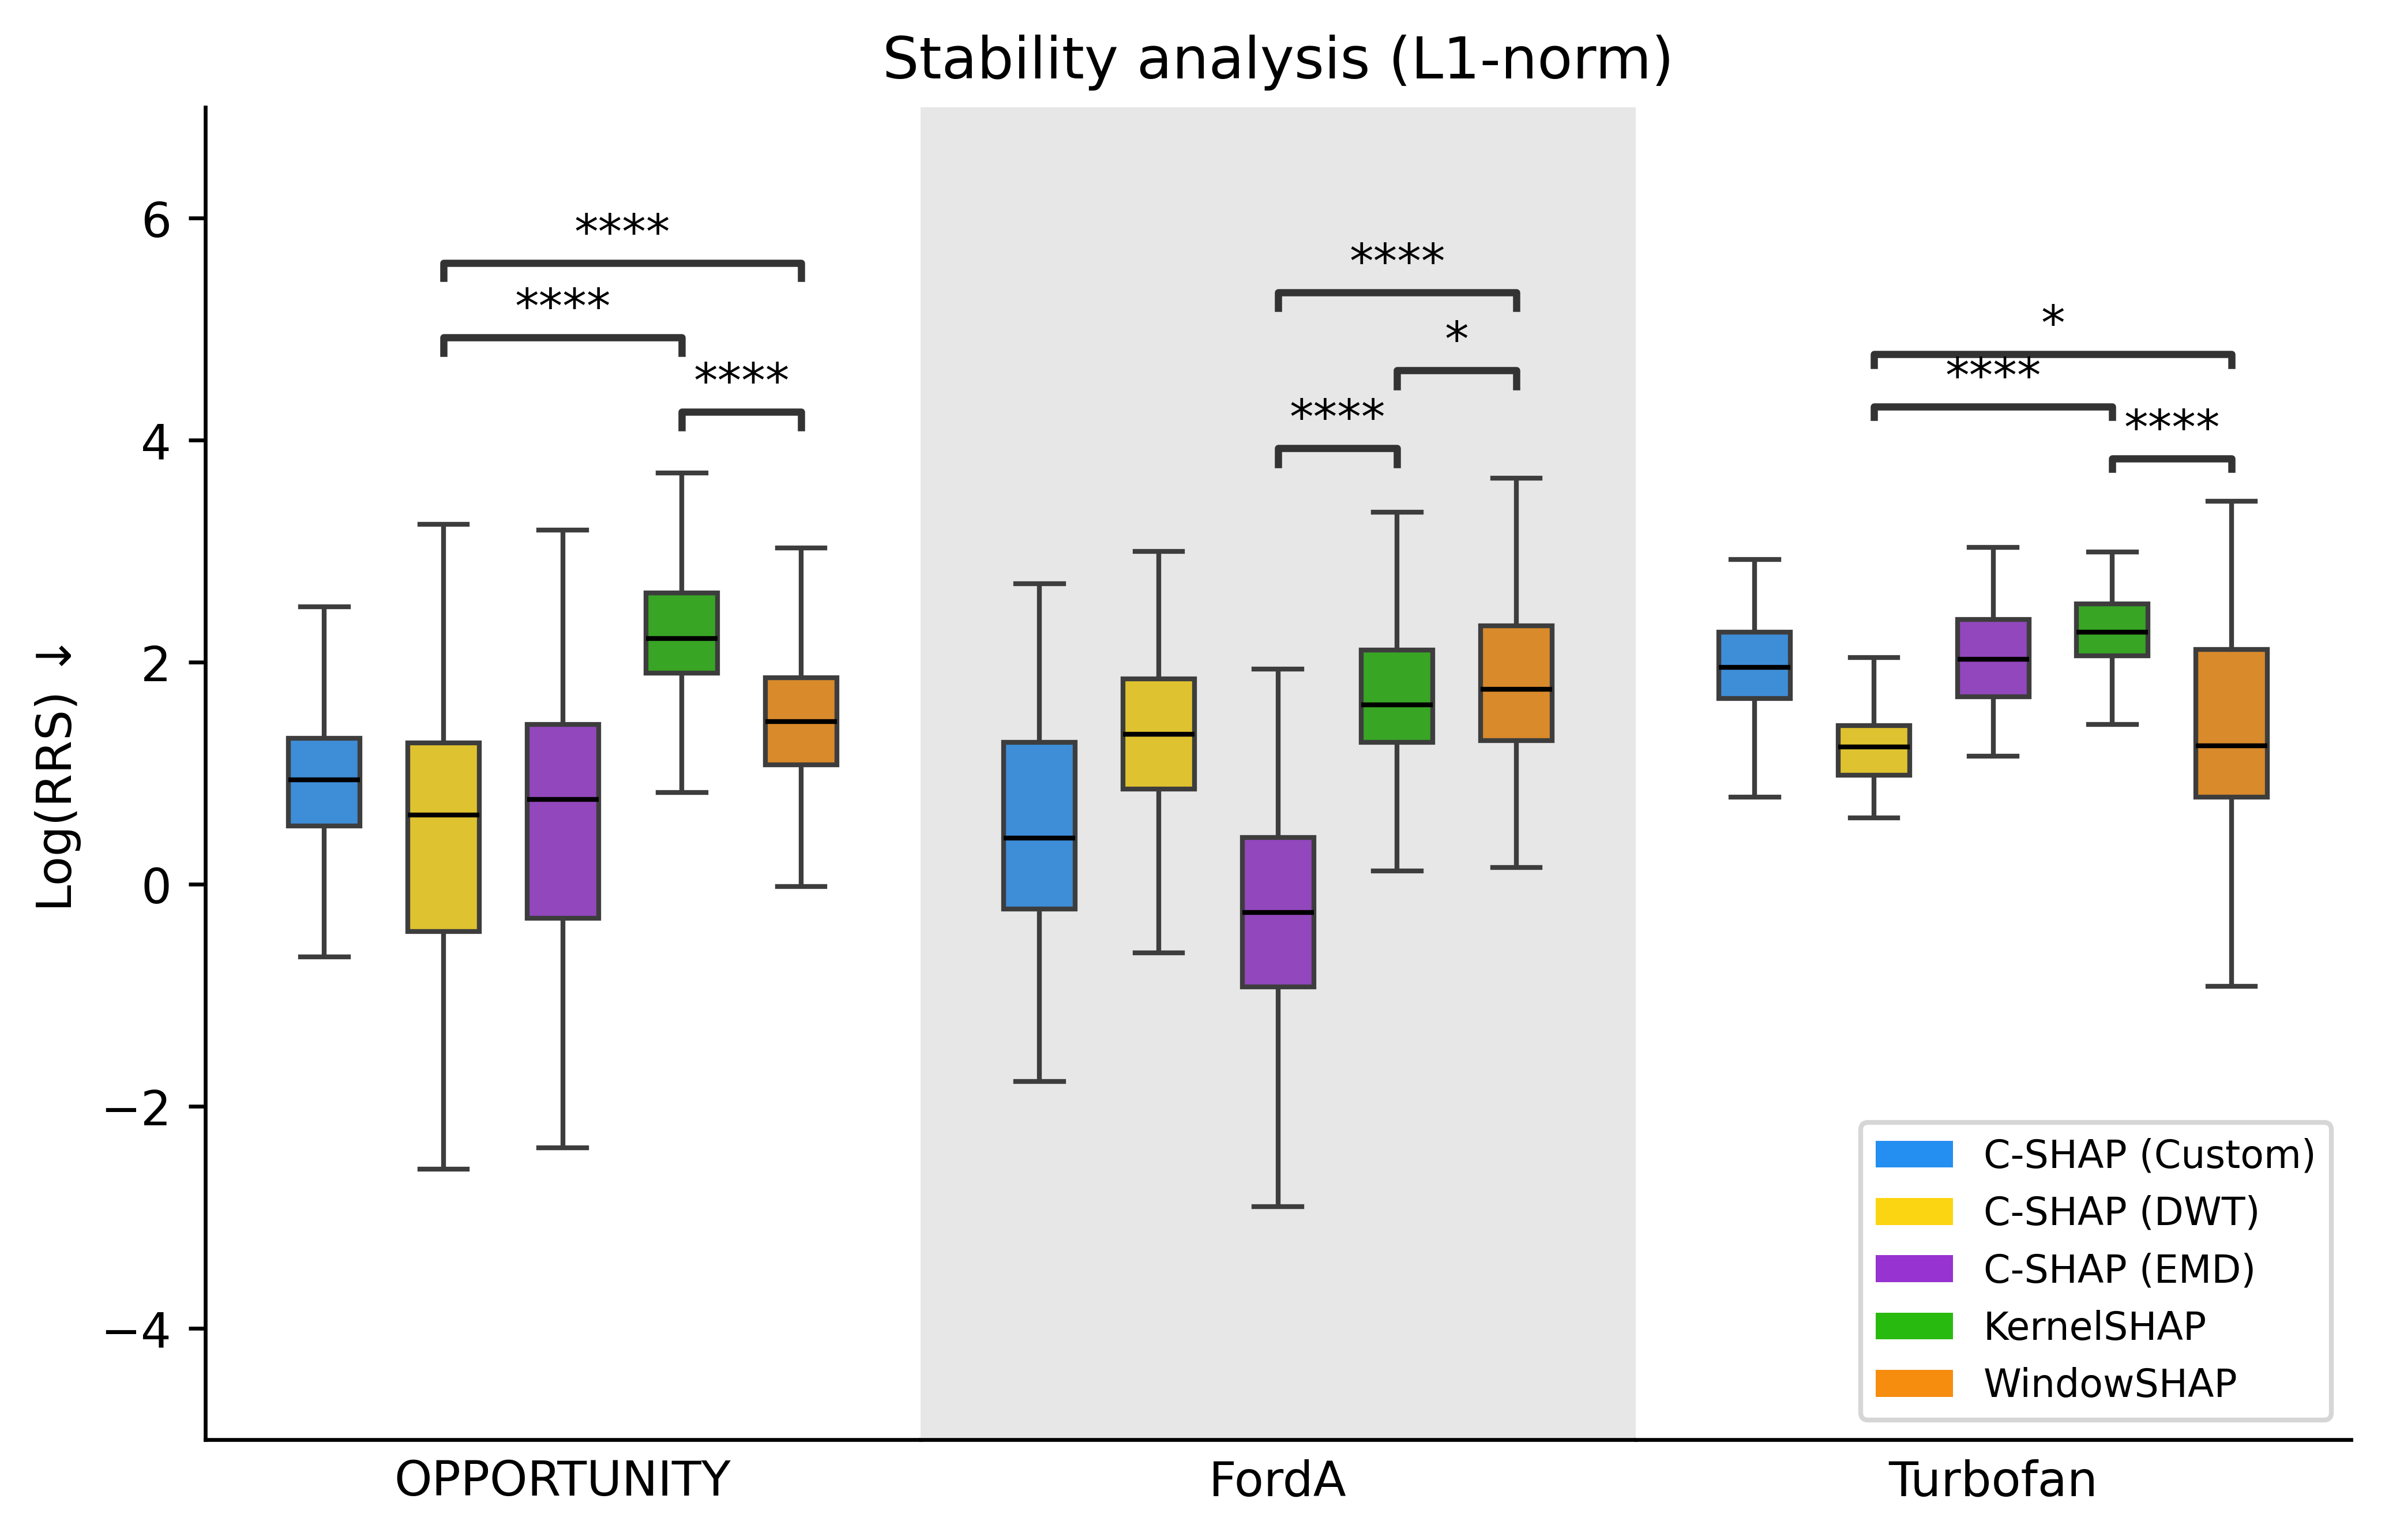

In [11]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_rel

methods = stability_nn_features['opportunity_uni'].keys()

# Initialize figure
fig, axes = plt.subplots(1, 3, dpi=600, figsize=(8, 5))

if metric == 'rrs':
    sub_colors = [colors[1], colors[0], colors[4], colors[3]]
else:
    sub_colors = [colors[1], colors[0], colors[4], colors[2],  colors[3]]
color_palette = {m: c for m, c in zip(methods, sub_colors)}

# Create boxplots representing the results for the different samples in each dataset
for i, dataset in enumerate(datasets):
    res = pd.DataFrame(stability_nn_features[dataset])
    boxplot_opp = sns.boxplot(res, palette=color_palette, ax=axes[i],
                        widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

    # Determine best C-SHAP method to focus statistical testing on
    mean_cshaps = {m: np.mean(res) for m, res in stability_nn_features[dataset].items() if 'cshap' in m}
    best_method = min(mean_cshaps, key=mean_cshaps.get)

    # Statistical testing
    if metric == 'rrs':
        pairs = [(best_method, 'windowshap_sliding')]
    else:
        pairs = [(best_method, 'kernelshap'), (best_method, 'windowshap_sliding'), ('kernelshap', 'windowshap_sliding')]
    annotator = Annotator(axes[i], pairs, data=res)
    annotator.configure(test='t-test_paired', text_format='star', loc='inside', verbose=False)
    annotator.apply_test(alternative='less')    # Two-sided t-test
    
    # Annotator does not handle ordering correctly, so we only use it for visualization and overwrite the p-values
    for annotation in annotator.annotations:
        g1, g2 = annotation.structs
        if np.mean(stability_nn_features[dataset][g1['label']]) > np.mean(stability_nn_features[dataset][g2['label']]):
            tts = ttest_rel(stability_nn_features[dataset][g2['label']], stability_nn_features[dataset][g1['label']], alternative='less')
        else:
            tts = ttest_rel(stability_nn_features[dataset][g1['label']], stability_nn_features[dataset][g2['label']], alternative='less')
        annotation.data.pvalue = tts.pvalue
        annotation.data.stat_value = tts.statistic
    annotator.annotate()

# Set legend
if metric == 'rrs':
    legend_elements = [Patch(facecolor=colors[1], label='C-SHAP (Custom)'),
                    Patch(facecolor=colors[0], label='C-SHAP (DWT)'),
                    Patch(facecolor=colors[4], label='C-SHAP (EMD)'), 
                    Patch(facecolor=colors[3], label='WindowSHAP')]
else:
    legend_elements = [Patch(facecolor=colors[1], label='C-SHAP (Custom)'),
                Patch(facecolor=colors[0], label='C-SHAP (DWT)'),
                Patch(facecolor=colors[4], label='C-SHAP (EMD)'), 
                Patch(facecolor=colors[2], label='KernelSHAP'), 
                Patch(facecolor=colors[3], label='WindowSHAP')]

# Annotate figure
if norm == 1:
    axes[1].set_title('Stability analysis (L1-norm)')
elif norm == 2:
    axes[1].set_title('Stability analysis (L2-norm)')

# Make axes look nice
for i, ax in enumerate(axes):
    ax.set_xticks([])
    ax.set_ylim(-5, 7)
    # ax.set_ylim(-10, 13)                  # Zoom out if necessary
    ax.set_xlim(-1, 5)

    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    if i > 0:
        ax.set_yticks([])
        ax.spines.left.set_visible(False)

# Label datasets
axes[0].set_xlabel('OPPORTUNITY')
axes[1].set_xlabel('FordA')
axes[2].set_xlabel('Turbofan')

# Create grey bar for visual distinction
axes[1].axvspan(-1, 5, facecolor='#D0D0D0', alpha=0.5)

# Set y label and legend
axes[0].set_ylabel('Log(RRS) ↓')
axes[2].legend(handles=legend_elements, loc='lower right', prop={'size': 8})

# Clean up space
fig.subplots_adjust(wspace=0)